In [ ]:
# Define Folder Paths

#Main Path
# main_path = "/Users/allisonpickle/Desktop/Test"

# #Subfolders
# folder_paths = { 
#     # f"{main_path}/Co_Cortical_AB",
#     # f"{main_path}/Co_Cortical_Ctrl",
#     # f"{main_path}/Co_Cortical_LPS",
#     # f"{main_path}/Co_Cortical_Lysis",
#     # f"{main_path}/Co_Hippo_AB",
#     # f"{main_path}/Co_Hippo_Ctrl",
#     # f"{main_path}/Co_Hippo_LPS",
#     # f"{main_path}/Co_Hippo_Lysis",
#     # f"{main_path}/Tri_Cortical_AB",
#     # f"{main_path}/Tri_Cortical_Ctrl",
#     # f"{main_path}/Tri_Cortical_LPS",
#     # f"{main_path}/Tri_Cortical_Lysis",
#     # f"{main_path}/Tri_Hippo_AB",
#     "/Users/allisonpickle/Desktop/Test/Tri_Ctrl_Cortical",
#     "/Users/allisonpickle/Desktop/Test/Tri_Hippo_LPS",
#     # f"{main_path}/Tri_Hippo_Lysis"
# }

folder_path = "/Users/allisonpickle/Desktop/Test",

In [ ]:
def Convert_czi_to_tiff(folder_path):
    import os
    import czifile
    from tifffile import imsave
    import shutil
    import cv2
    import numpy as np

    print(f"Beginning czi to tiff conversion...")
    
    # Create the "CZI" folder in each folder path
    czi_folder_path = os.path.join(folder_path, "CZI")
    os.makedirs(czi_folder_path, exist_ok=True)

    for filename in os.listdir(folder_path):
        if filename.endswith(".czi"):
            czi_path = os.path.join(folder_path, filename)
            with czifile.CziFile(czi_path) as czi:
                image_arrays = czi.asarray()
                for channel_idx, channel_image in enumerate(image_arrays):
                    # Convert the image to 16-bit
                    channel_image_16bit = cv2.normalize(channel_image, None, 0, 65535, cv2.NORM_MINMAX, dtype=cv2.CV_16U)
                    
                    tiff_path = os.path.splitext(czi_path)[0] + f"_C_{channel_idx}.tiff"
                    imsave(tiff_path, channel_image_16bit)

            # Move the CZI files to the "CZI" folder
            new_czi_path = os.path.join(czi_folder_path, filename)
            shutil.move(czi_path, new_czi_path)

# Loop through every folder path and convert CZI files to TIFF
Convert_czi_to_tiff("/Users/allisonpickle/Desktop/Test")


In [ ]:
from __future__ import print_function
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from scipy import ndimage
import argparse
import cv2
import matplotlib.pyplot as plt
import numpy as np
import imutils
import os
import pandas as pd
from PIL import Image
import os
import numpy as np
from skimage import restoration 
import matplotlib.pyplot as plt
from tifffile import imsave

In [ ]:
from PIL import Image
import os
import numpy as np
from skimage import restoration 
import matplotlib.pyplot as plt
from tifffile import imsave

def subtract_background(folder_path):
    """Subtracts background from images in a folder using the rolling ball algorithm

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the images

    Returns
    -------
    None
    """
     # Get a list of all image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Create a folder to store the result images
    result_folder = os.path.join(folder_path, 'Processed_Images')
    os.makedirs(result_folder, exist_ok=True)


    # Iterate over each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        # Open the image file
        image = Image.open(image_path)

        # Convert the image to a numpy array and cast it to uint16
        image = np.array(image).astype(np.uint16)

        # Apply Gaussian Filtering
        image = cv2.GaussianBlur(image, (3, 3), 0)

        # Perform the desired image processing operations
        background = restoration.rolling_ball(image, radius=50)
        result_image = image - background

        # Display the original image and the resulting background-subtracted image side by side
        # fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        # axes[0].imshow(image, cmap='gray')
        # axes[0].set_title('Original Image')
        # axes[0].axis('off')
        # axes[1].imshow(result_image, cmap='gray')
        # axes[1].set_title('Background-Subtracted Image')
        # axes[1].axis('off')
        # plt.show()

        # # Convert the array to 8-bit unsigned integers
        # result_image = result_image.astype(np.uint8)

        # Save result_image to result_folder with the same filename
        result_image_path = os.path.join(result_folder, image_file)
        imsave(result_image_path, result_image)


subtract_background("/Users/allisonpickle/Desktop/Test")

In [ ]:
folder_path = "/Users/allisonpickle/Desktop/Test/Processed_Images"
# MEAN SHIFT ARRAY
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

def mean_shift_array(folder_path):
	"""Applies mean shift filtering to images in a folder and saves the resulting images to a new folder

	Parameters
	----------
	folder_path : str
		Path to the folder containing the images

	Returns
	-------
	None
	"""
	image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

	# Iterate over each image file
	for image_file in image_files:
		# Check if the image file ends with C_0
		if image_file.endswith('C_0.tiff'):
			# Construct the full path to the image file
			image_path = os.path.join(folder_path, image_file)

			# Read the image
			image = cv2.imread(image_path)

			# Apply mean shift filtering
			shifted_1 = cv2.pyrMeanShiftFiltering(image, 30, 30) 
			shifted_2 = cv2.pyrMeanShiftFiltering(image, 30, 20) 
			shifted_3 = cv2.pyrMeanShiftFiltering(image, 30, 10)
			shifted_4 = cv2.pyrMeanShiftFiltering(image, 20, 30) 
			shifted_5 = cv2.pyrMeanShiftFiltering(image, 20, 20) 
			shifted_6 = cv2.pyrMeanShiftFiltering(image, 20, 10) 
			shifted_7 = cv2.pyrMeanShiftFiltering(image, 10, 30) 
			shifted_8 = cv2.pyrMeanShiftFiltering(image, 10, 20)
			shifted_9 = cv2.pyrMeanShiftFiltering(image, 10, 10) 

			# Create a figure with a 3x3 grid of subplots
			fig, axes = plt.subplots(3, 3, figsize=(15, 15))

			# Iterate over each shifted image and its respective sp and sr values
			for i, (shifted, sp, sr) in enumerate(zip([shifted_1, shifted_2, shifted_3, shifted_4, shifted_5, shifted_6, shifted_7, shifted_8, shifted_9], [30, 30, 30, 20, 20, 20, 10, 10, 10], [30, 20, 10, 30, 20, 10, 30, 20, 10])):
				# Calculate the row and column indices for the subplot
				row = i // 3
				col = i % 3

				# Display the shifted image in the corresponding subplot
				axes[row, col].imshow(shifted, cmap='gray')
				axes[row, col].set_title(f"sp={sp}, sr={sr}")  # Set the figure title as sp and sr
				axes[row, col].axis('off')

			# Adjust the spacing between subplots
			plt.subplots_adjust(wspace=0.1, hspace=0.1)

			# Create the "Mean_Shift_Arrays" folder in the specified folder path
			output_folder = os.path.join(folder_path, "Mean Shift Arrays")
			os.makedirs(output_folder, exist_ok=True)

			# Save the plot to the "Mean_Shift_Arrays" folder
			plot_name = os.path.splitext(image_file)[0] + "_mean_shift.png"
			plot_path = os.path.join(output_folder, plot_name)
			plt.savefig(plot_path, bbox_inches='tight', dpi=300, pad_inches=0.1, transparent=False)

			# Show the plot
			plt.show()
			plt.close()
			# ~30 seconds per image



In [ ]:
# APPLY MEAN SHIFT FILTER + OTSU THRESHOLD

def Apply_Mean_Shift_Test(folder_path, SR, CR):
	import os
	import cv2
	import matplotlib.pyplot as plt
	import numpy as np
	
	# Get a list of all image files in the folder
	image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

	# Iterate over each image file
	for image_file in image_files:
		# Construct the full path to the image file
		image_path = os.path.join(folder_path, image_file)

		# Read the image
		image = cv2.imread(image_path)

		# Apply Gaussian Filtering
		blurred = cv2.GaussianBlur(image, (3, 3), 0)

		# Apply mean shift filtering
		shifted = cv2.pyrMeanShiftFiltering(blurred, SR, CR) ## INPUT SPATIAL RADIUS AND COLOR RADIUS

		# Otsu's thresholding
		gray = cv2.cvtColor(shifted, cv2.COLOR_BGR2GRAY)
		thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)[1]
		
		# Create the "thresholded" folder in the specified folder path
		output_folder = os.path.join(folder_path, "Thresholded")
		os.makedirs(output_folder, exist_ok=True)

		# Save the thresholded image to the "thresholded" folder
		output_path = os.path.join(output_folder, image_file)
		cv2.imwrite(output_path, thresh)

		
		# Create a figure with two subplots
		fig, axes = plt.subplots(1, 3, figsize=(20, 10))

		# Display the first image
		axes[0].imshow(image, cmap='gray')
		axes[0].set_title(image_file)  # Set the image title as the file name
		axes[0].axis('off')
		
		# Display the threshold image
		axes[1].imshow(gray, cmap='gray')
		axes[1].axis('off')
		
		# Display the threshold image
		axes[2].imshow(thresh, cmap='gray')
		axes[2].axis('off')

		plt.show()
		plt.close()


In [ ]:
folder_path = "/Users/allisonpickle/Desktop/Test/Tri_Ctrl_Cortical/thresholded"

In [ ]:
# EROSION ARRAY TEST
folder_path = "/Users/allisonpickle/Desktop/Test/Processed_Images/thresholded"

def Erosion_Test(folder_path, S1, S2, S3):
	import os
	import cv2
	import matplotlib.pyplot as plt
	import numpy as np
	# Get a list of all image files in the folder
	image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

	# Iterate over each image file
	for image_file in image_files:
		# Skip DAPI Images
		if not image_file.endswith('C_0.tiff'):
			continue

		image_path = os.path.join(folder_path, image_file)

		# Read the image
		image = cv2.imread(image_path)

		# Define the size of the structuring elements
		structuring_element_sizes = [6, 8, 10]

		# Create the figure and subplots outside of the loop
		fig, axes = plt.subplots(1, len(structuring_element_sizes) + 1, figsize=(20, 10))
		plt.subplots_adjust(wspace=0.1, hspace=0.1)

		# Display the original image in the first column
		axes[0].imshow(image, cmap='gray')
		axes[0].set_title(image_file)  # Set the image title as the file name
		axes[0].axis('off')	

		# Iterate over each structuring element size
		for i, size in enumerate(structuring_element_sizes):
			# Create the structuring element
			structuring_element = cv2.getStructuringElement(cv2.MORPH_RECT, (size, size))
			
			# Perform the erosion
			eroded_image = cv2.erode(image, structuring_element)
		
				# Display the eroded images in the columns next to the original image
			axes[i+1].imshow(eroded_image, cmap='gray')
			axes[i+1].set_title(f"Structuring Element Size: {size}")  # Set the image title with the structuring element size
			axes[i+1].axis('off')

		# Create the folder in the specified folder path
		output_folder = os.path.join(folder_path, "Eroded_Arrays")
		os.makedirs(output_folder, exist_ok=True)

			# Save the plot to the folder
		plot_name = os.path.splitext(image_file)[0] + "_Live_Eroded.png"
		plot_path = os.path.join(output_folder, plot_name)
		plt.savefig(plot_path, bbox_inches='tight', dpi=300, pad_inches=0.1, transparent=False)

		plt.show()
		plt.close()
		
		# # Create an empty DataFrame
		# contour_table = pd.DataFrame(columns=['Image Name', 'Live', 'Total'])
		# # Create an empty DataFrame
		# contour_table = pd.DataFrame(columns=['Image Name', 'Live', 'Total'])

		# D = ndimage.distance_transform_edt(thresh)
		# coords = peak_local_max(D, min_distance=10, labels=thresh) ##IMPUT MIN DISTANCE

		# # Create a new array of the same shape as `thresh`, filled with False
		# localMax = np.zeros_like(thresh, dtype=bool)

		# # Set the peaks to True
		# for coord in coords:
		# 	localMax[tuple(coord)] = True

		# # perform a connected component analysis on the local peaks,
		# # using 8-connectivity, then apply the Watershed algorithm
		# markers = ndimage.label(localMax, structure=np.ones((3, 3)))[0]
		# labels = watershed(-D, markers, mask=thresh)
	# print("[INFO] {} unique segments found".format(len(np.unique(labels)) - 1))

In [ ]:
# APPLY EROSION
folder_path = "/Users/allisonpickle/Desktop/Test/Processed_Images/thresholded"
image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

# Iterate over each image file
for image_file in image_files:
    # Skip DAPI Images
    if not image_file.endswith('C_0.tiff'):
        continue

    image_path = os.path.join(folder_path, image_file)

    # Read the image
    image = cv2.imread(image_path)

    # Define the size of the structuring elements
    structuring_element_size = 10

    # Create the structuring element
    structuring_element = cv2.getStructuringElement(cv2.MORPH_RECT, (structuring_element_size, structuring_element_size))

    # Perform the erosion
    eroded_image = cv2.erode(image, structuring_element)

    # Save the eroded image with the original file name
    eroded_image_path = os.path.join(folder_path, image_file)
    cv2.imwrite(eroded_image_path, eroded_image)


In [ ]:
import numpy as np
from basicpy import BaSiC
from matplotlib import pyplot as plt
import os
from tifffile import imsave
import os
from tifffile import imread, imwrite

In [ ]:
def optimize_contrast(folder_path):
    import skimage
    from skimage import io, exposure
    import matplotlib.pyplot as plt
    import os
    import numpy as np    

    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Iterate over each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        img = skimage.io.imread(image_path)

        # Normalize the image to be between -1 and 1
        img = img / np.max(np.abs(img))

        # Optimize the contrast of the image
        img_optimized = exposure.equalize_adapthist(img)

        # Convert the image to 16-bit
        img_optimized = img_as_uint(img_optimized)

        # Specify the file path of the optimized image
        optimized_image_path = os.path.join(folder_path, image_file)

        # Save the optimized image
        skimage.io.imsave(optimized_image_path, img_optimized)

        # Display the original image and the optimized image side by side
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(img, cmap='gray')
        axes[0].set_title('Original Image')
        axes[0].axis('off')
        axes[1].imshow(img_optimized, cmap='gray')
        axes[1].set_title('Optimized Image')
        axes[1].axis('off')
        plt.show()

optimize_contrast("/Users/allisonpickle/Desktop/Test/Tri_Ctrl_Cortical/CZI")

In [1]:
def Calculate_Live_Dead(folder_path, SR, CR, Erosion_Size, Minimum_distance):
	import os	
	import cv2
	import matplotlib.pyplot as plt
	import numpy as np
	from skimage.feature import peak_local_max
	from skimage.segmentation import watershed
	from scipy import ndimage
	import imutils
	import pandas as pd
	from tifffile import imsave

	image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

	# Create an empty DataFrame
	contour_table = pd.DataFrame(columns=['Image Name', 'Live', 'Total', 'Live %'])

	# Iterate over each image file
	for image_file in image_files:
		# Construct the full path to the image file
		image_path = os.path.join(folder_path, image_file)

		image = cv2.imread(image_path)

		# Apply Gaussian Filtering
		image = cv2.GaussianBlur(image, (3, 3), 0)

		# Apply mean shift filtering
		shifted = cv2.pyrMeanShiftFiltering(image, SR, CR) ## INPUT SPATIAL RADIUS AND COLOR RADIUS

		# Otsu's thresholding
		gray = cv2.cvtColor(shifted, cv2.COLOR_BGR2GRAY)
		thresh = cv2.threshold(gray, 0, 255,
							cv2.THRESH_BINARY | cv2.THRESH_OTSU)[1]

		# Skip DAPI Images
		if image_file.endswith('C_0.tiff'):

			structuring_element_size = Erosion_Size
			structuring_element = cv2.getStructuringElement(cv2.MORPH_RECT, (structuring_element_size, structuring_element_size))
			eroded_image = cv2.erode(thresh, structuring_element)

			thresh = eroded_image

		D = ndimage.distance_transform_edt(thresh)
		coords = peak_local_max(D, min_distance=Minimum_distance, labels=thresh) ##INPUT MIN DISTANCE

		# Create a new array of the same shape as `thresh`, filled with False
		localMax = np.zeros_like(thresh, dtype=bool)

		# Set the peaks to True
		for coord in coords:
			localMax[tuple(coord)] = True

		# perform a connected component analysis on the local peaks,
		# using 8-connectivity, then appy the Watershed algorithm
		markers = ndimage.label(localMax, structure=np.ones((3, 3)))[0]
		labels = watershed(-D, markers, mask=thresh)
		print("[INFO] {} unique segments found".format(len(np.unique(labels)) - 1))

		for label in np.unique(labels):
			# if the label is zero, we are examining the 'background'
			# so simply ignore it
			if label == 0:
				continue
			# otherwise, allocate memory for the label region and draw
			# it on the mask
			mask = np.zeros(gray.shape, dtype="uint8")
			mask[labels == label] = 255
			# detect contours in the mask and grab the largest one
			cnts = cv2.findContours(mask.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
			cnts = imutils.grab_contours(cnts)
			c = max(cnts, key=cv2.contourArea)
			cv2.drawContours(image, [c], -1, (0, 255, 0), 2)
			# cv2.circle(image, (int(x), int(y)), int(r), (0, 255, 0), 2)

		num_contours = len(np.unique(labels)) - 1

				# remove everything after the last underscore in the image name
				# find index of last underscore
		underscore_index = image_file.rfind('_')
		image_name  = image_file[:underscore_index]
		cntid = image_file.split('_')[-1][0]
				# print(image_name)
				# print(cntid)
		
		column_names = {'0': 'Live', '1': 'Total'}
		if image_name in contour_table['Image Name'].values:
			contour_table.loc[contour_table['Image Name'] == image_name, column_names[cntid]] = num_contours
		else:
			contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)

		# Divide the Live by the Total to get the percentage of live cells
		contour_table['Live'] = contour_table['Live'].astype(float)
		contour_table['Total'] = contour_table['Total'].astype(float)
		contour_table['Live %'] = (contour_table['Live'] / contour_table['Total']) * 100

		# Save the contour_table DataFrame to an Excel file in the folder directory
		excel_file_path = os.path.join(folder_path, "Contour Count.xlsx")
		contour_table.to_excel(excel_file_path, index=False)

		# Create a 3 by 1 subplot with increased size and resolution
		fig, axes = plt.subplots(1, 3, figsize=(15, 5))

		# Display the shifted image using Matplotlib
		axes[0].imshow(cv2.cvtColor(shifted, cv2.COLOR_BGR2RGB))
		axes[0].axis('off')

		# Display the grayscale image using Matplotlib
		axes[1].imshow(thresh, cmap='gray')
		axes[1].axis('off')

		# Show the output image using Matplotlib
		axes[2].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
		axes[2].axis('off')

		fig_name = os.path.splitext(image_file)[0] + "_Count"
			# Adjust the spacing between subplots
		plt.subplots_adjust(wspace=0.1)
				# Save the figure to the original image directory
				# Create a new folder called "Count" in the specified folder path
		count_folder_path = os.path.join(folder_path, "Count")
		os.makedirs(count_folder_path, exist_ok=True)

				# Save the figure to the "Count" folder
		fig_path = os.path.join(count_folder_path, fig_name + ".png")
		plt.savefig(fig_path, bbox_inches='tight', dpi=300, pad_inches=0.1, transparent=True)

		plt.show()

[INFO] 316 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_1397/1571939766.py:91: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


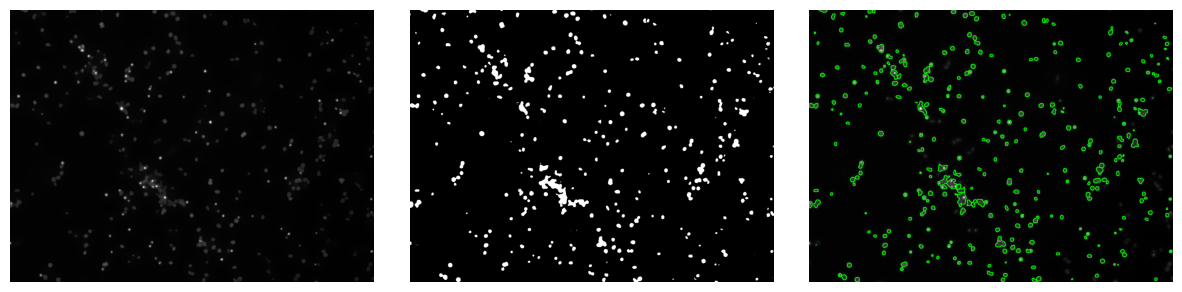

[INFO] 188 unique segments found


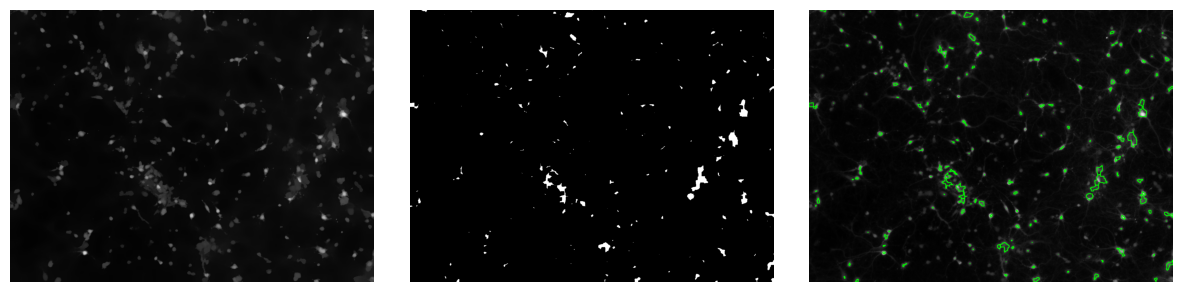

[INFO] 240 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_1397/1571939766.py:91: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


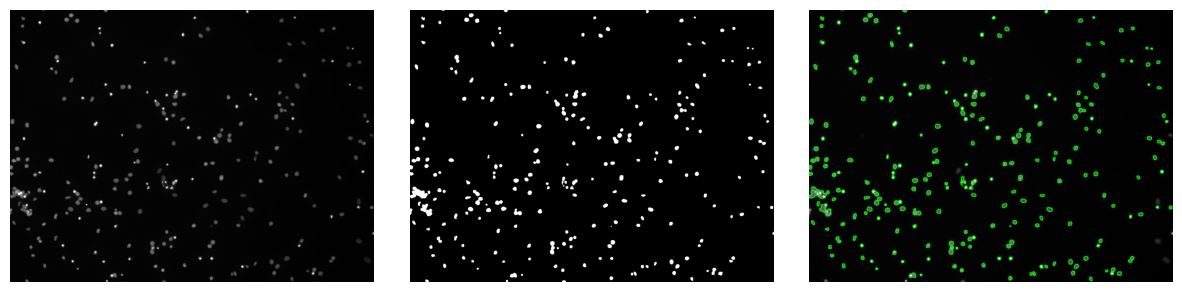

[INFO] 260 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_1397/1571939766.py:91: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


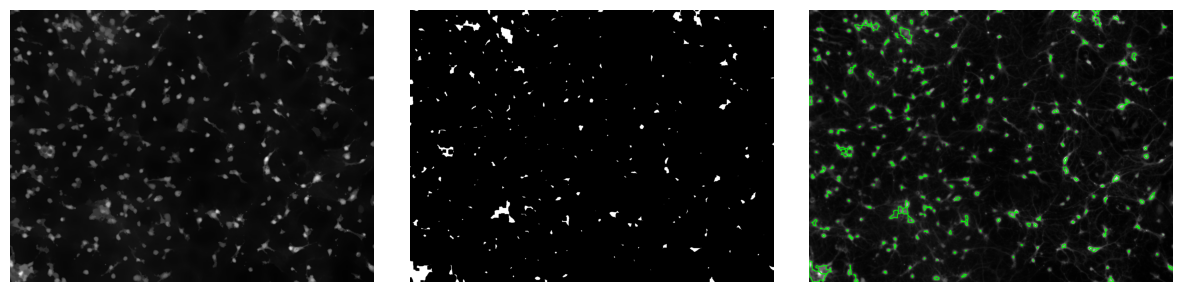

[INFO] 327 unique segments found


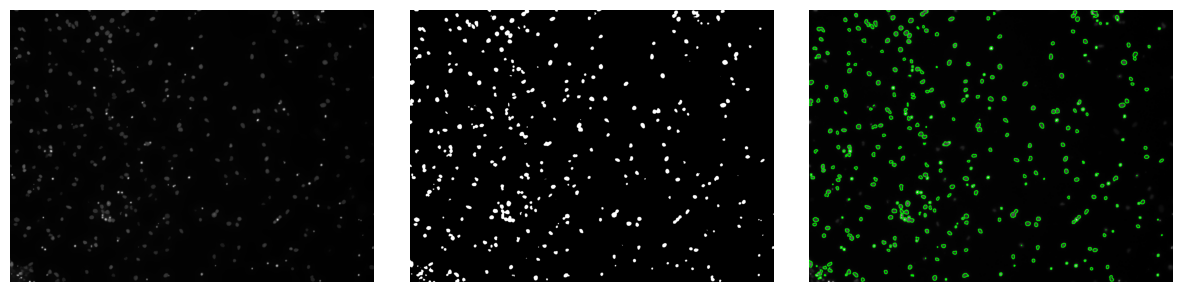

[INFO] 143 unique segments found


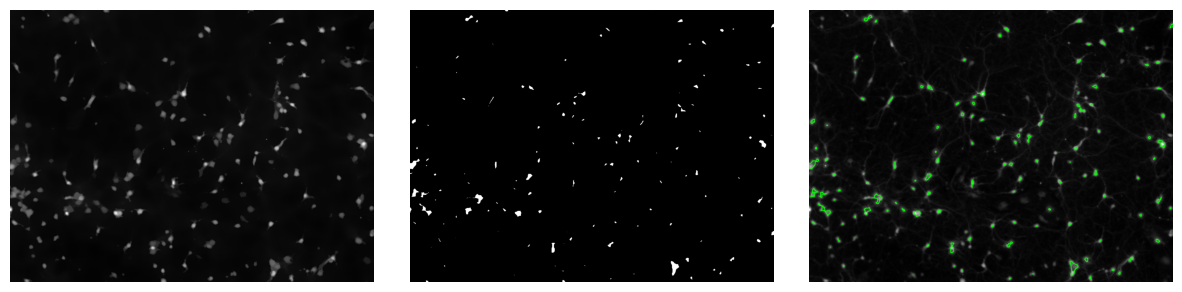

[INFO] 219 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_1397/1571939766.py:91: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


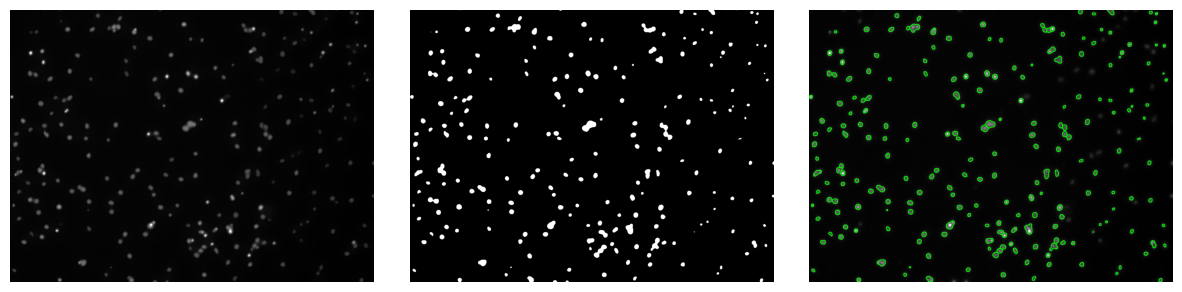

[INFO] 205 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_1397/1571939766.py:91: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


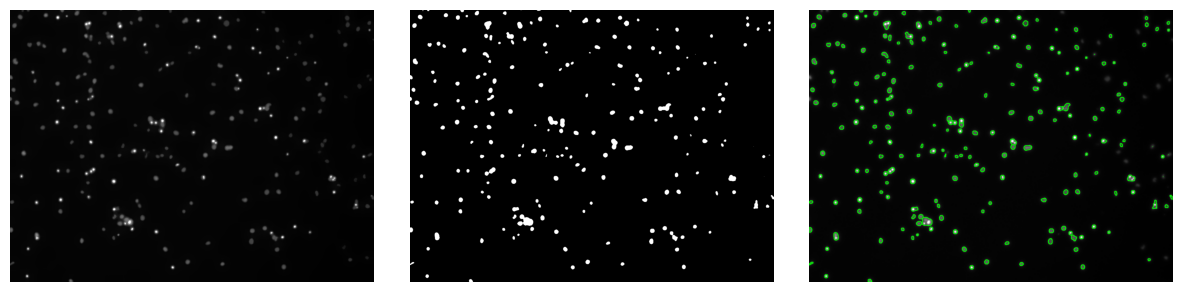

[INFO] 123 unique segments found


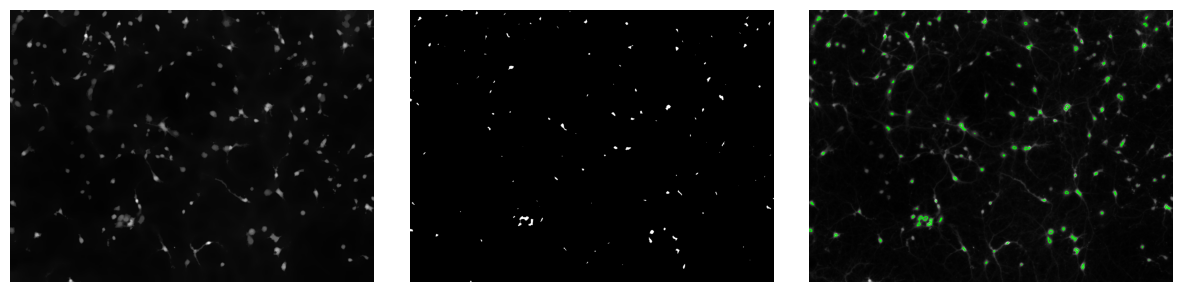

[INFO] 168 unique segments found


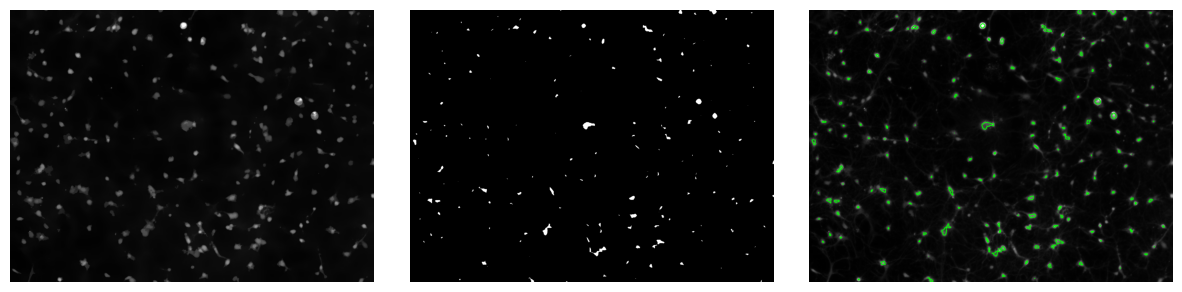

[INFO] 426 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_1397/1571939766.py:91: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


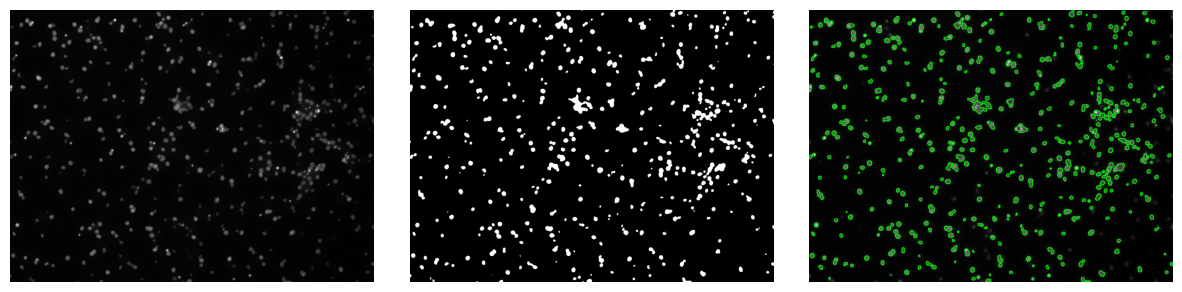

[INFO] 319 unique segments found


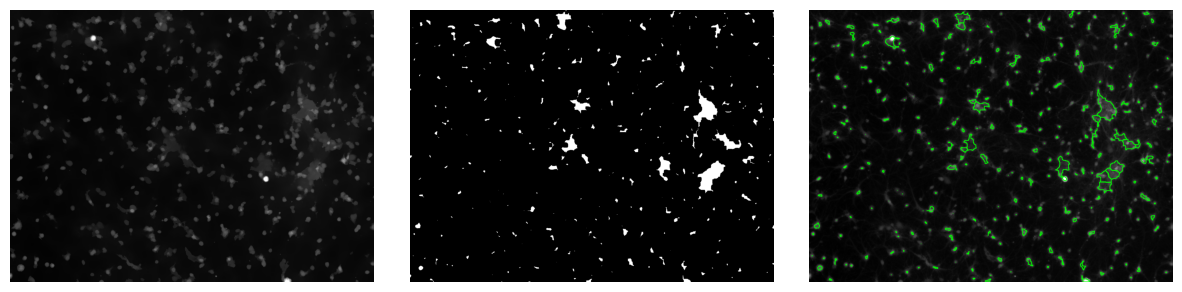

In [3]:
folder_path = "/Users/allisonpickle/Desktop/IL_10_Test"
SR = 20
CR = 20
Erosion_Size = 10
Minimum_distance = 10

Calculate_Live_Dead(folder_path, SR, CR, Erosion_Size, Minimum_distance)

In [ ]:

num_contours = len(np.unique(labels)) - 1

		# remove everything after the last underscore in the image name
		# find index of last underscore
underscore_index = image_file.rfind('_')
image_name  = image_file[:underscore_index]
cntid = image_file.split('_')[-1][0]
		# print(image_name)
		# print(cntid)
		
		# add image name and number of contours to the dataframe. If the image name is already in the dataframe, add the count to the appropriate column
if image_name in contour_table['Image Name'].values:
			contour_table.loc[contour_table['Image Name'] == image_name, f'Count {cntid}'] = num_contours
else:
			contour_table = contour_table.append({'Image Name': image_name, f'Count {cntid}': num_contours}, ignore_index=True)


		# Save the contour_table DataFrame to an Excel file in the folder directory
excel_file_path = os.path.join(folder_path, "Contour Count.xlsx")
contour_table.to_excel(excel_file_path, index=False)


In [ ]:
	# Create a 3 by 1 subplot with increased size and resolution
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=300)	

		# Display the shifted image using Matplotlib
axes[0].imshow(cv2.cvtColor(shifted, cv2.COLOR_BGR2RGB))
axes[0].axis('off')

		# Display the grayscale image using Matplotlib
axes[1].imshow(thresh, cmap='gray')
axes[1].axis('off')

		# Show the output image using Matplotlib
axes[2].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[2].axis('off')

fig_name = os.path.splitext(image_file)[0] + "_Count"
		# Adjust the spacing between subplots
plt.subplots_adjust(wspace=0.1)
		# Save the figure to the original image directory
		# Create a new folder called "Count" in the specified folder path
count_folder_path = os.path.join(folder_path, "Count")
os.makedirs(count_folder_path, exist_ok=True)

		# Save the figure to the "Count" folder
fig_path = os.path.join(count_folder_path, fig_name + ".png")
plt.savefig(fig_path, bbox_inches='tight', dpi=300, pad_inches=0.1, transparent=True)
		# # Close the plot
		# plt.close()
		# Show the plot
plt.show()

In [22]:
def Calculate_Live_Dead(folder_path, SR, CR, Erosion_Size, Minimum_Distance):
	import os	
	import cv2
	import matplotlib.pyplot as plt
	import numpy as np
	from skimage.feature import peak_local_max
	from skimage.segmentation import watershed
	from scipy import ndimage
	import imutils
	import pandas as pd
	from tifffile import imsave


	image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

	# Create an empty DataFrame
	contour_table = pd.DataFrame(columns=['Image Name', 'Live', 'Total'])

	# Iterate over each image file
	for image_file in image_files:
		# Construct the full path to the image file
		image_path = os.path.join(folder_path, image_file)

		image = cv2.imread(image_path)

		# Apply Gaussian Filtering
		image = cv2.GaussianBlur(image, (3, 3), 0)

		# Apply mean shift filtering
		shifted = cv2.pyrMeanShiftFiltering(image, SR, CR) ## INPUT SPATIAL RADIUS AND COLOR RADIUS

		# Otsu's thresholding
		gray = cv2.cvtColor(shifted, cv2.COLOR_BGR2GRAY)
		thresh = cv2.threshold(gray, 0, 255,
							cv2.THRESH_BINARY | cv2.THRESH_OTSU)[1]

		# Skip DAPI Images
		if image_file.endswith('C_0.tiff'):

			structuring_element_size = Erosion_Size
			structuring_element = cv2.getStructuringElement(cv2.MORPH_RECT, (structuring_element_size, structuring_element_size))
			eroded_image = cv2.erode(thresh, structuring_element)

			thresh = eroded_image

		D = ndimage.distance_transform_edt(thresh)
		coords = peak_local_max(D, min_distance=Minimum_Distance, labels=thresh) ##INPUT MIN DISTANCE

		# Create a new array of the same shape as `thresh`, filled with False
		localMax = np.zeros_like(thresh, dtype=bool)

		# Set the peaks to True
		for coord in coords:
			localMax[tuple(coord)] = True

		# perform a connected component analysis on the local peaks,
		# using 8-connectivity, then appy the Watershed algorithm
		markers = ndimage.label(localMax, structure=np.ones((3, 3)))[0]
		labels = watershed(-D, markers, mask=thresh)
		print("[INFO] {} unique segments found".format(len(np.unique(labels)) - 1))

		for label in np.unique(labels):
			# if the label is zero, we are examining the 'background'
			# so simply ignore it
			if label == 0:
				continue
			# otherwise, allocate memory for the label region and draw
			# it on the mask
			mask = np.zeros(gray.shape, dtype="uint8")
			mask[labels == label] = 255
			# detect contours in the mask and grab the largest one
			cnts = cv2.findContours(mask.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
			cnts = imutils.grab_contours(cnts)
			c = max(cnts, key=cv2.contourArea)
			cv2.drawContours(image, [c], -1, (0, 255, 0), 2)
			# cv2.circle(image, (int(x), int(y)), int(r), (0, 255, 0), 2)

		num_contours = len(np.unique(labels)) - 1

				# remove everything after the last underscore in the image name
				# find index of last underscore
		underscore_index = image_file.rfind('_')
		image_name  = image_file[:underscore_index]
		cntid = image_file.split('_')[-1][0]
				# print(image_name)
				# print(cntid)
		
		column_names = {'0': 'Live', '1': 'Total'}
		if image_name in contour_table['Image Name'].values:
			contour_table.loc[contour_table['Image Name'] == image_name, column_names[cntid]] = num_contours
		else:
			contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


		# Create a 3 by 1 subplot with increased size and resolution
		fig, axes = plt.subplots(1, 3, figsize=(15, 5))

		# Display the shifted image using Matplotlib
		axes[0].imshow(cv2.cvtColor(shifted, cv2.COLOR_BGR2RGB))
		axes[0].axis('off')

		axes[1].imshow(thresh, cmap='gray')
		axes[1].axis('off')

		axes[2].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
		axes[2].axis('off')
		#  Save Excel sheet to folder_path
		excel_file_path = os.path.join("/Users/allisonpickle/Desktop/", "Contour Count.xlsx")
		contour_table.to_excel(excel_file_path, index=False)
		
		fig_name = os.path.splitext(image_file)[0] + "_Count"
			# Adjust the spacing between subplots
		plt.subplots_adjust(wspace=0.1)
		
		count_folder_path = os.path.join(folder_path, "Count")
		os.makedirs(count_folder_path, exist_ok=True)

				# Save the figure to the "Count" folder
		fig_path = os.path.join(count_folder_path, fig_name + ".png")
		plt.savefig(fig_path, bbox_inches='tight', dpi=300, pad_inches=0.1, transparent=True)

		plt.show()


[INFO] 361 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_10303/185479405.py:92: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


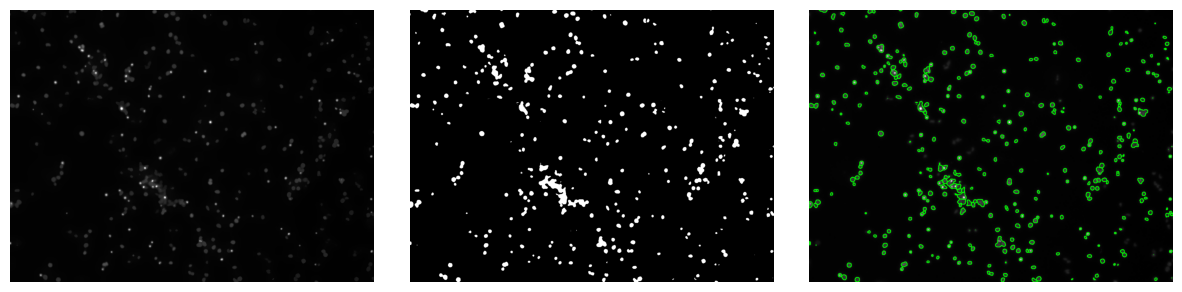

[INFO] 244 unique segments found


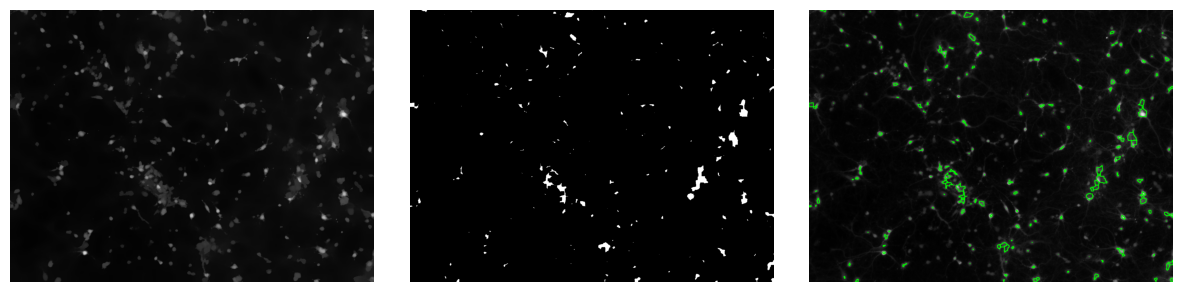

[INFO] 260 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_10303/185479405.py:92: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


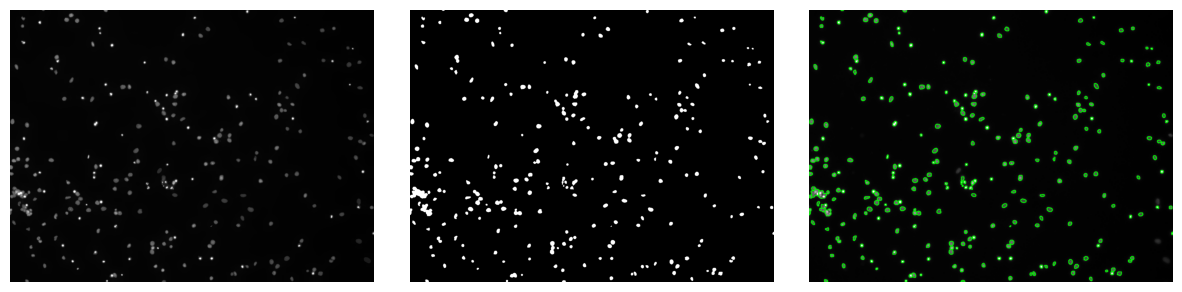

[INFO] 336 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_10303/185479405.py:92: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


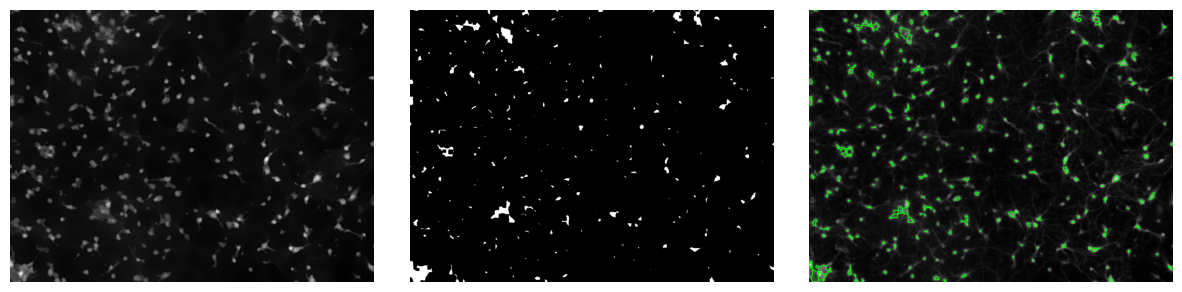

[INFO] 371 unique segments found


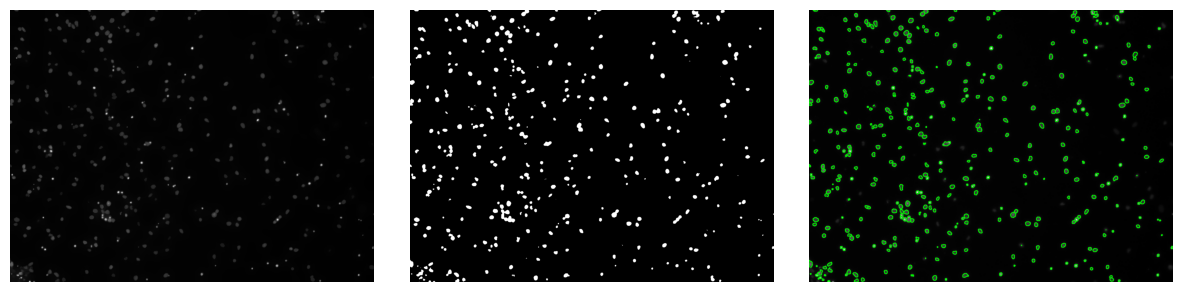

[INFO] 173 unique segments found


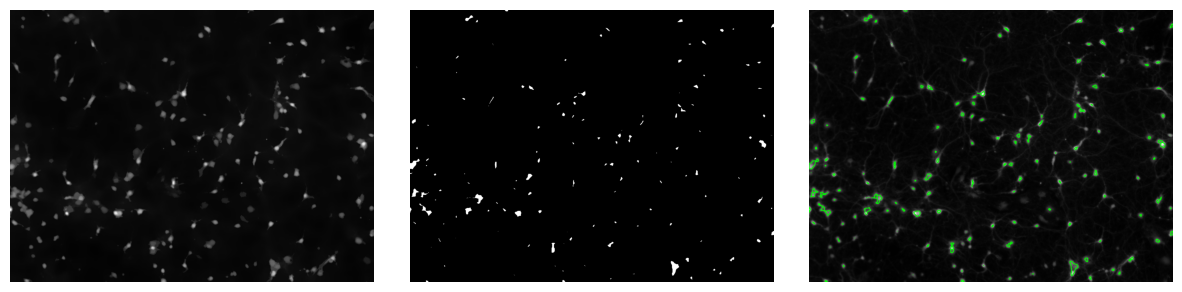

[INFO] 232 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_10303/185479405.py:92: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


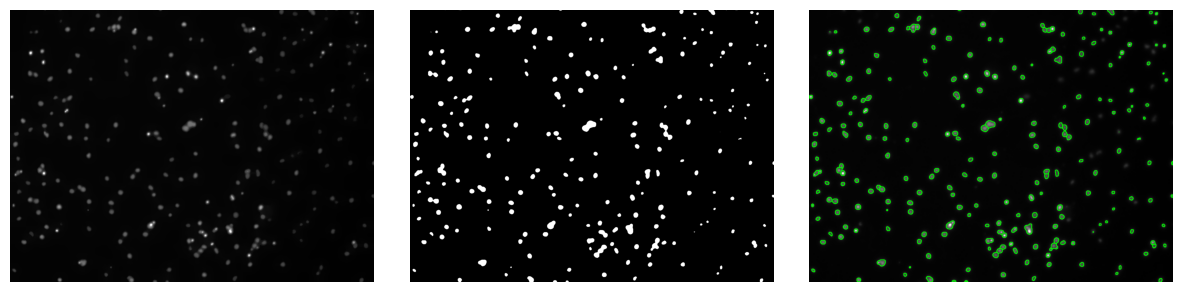

[INFO] 220 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_10303/185479405.py:92: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


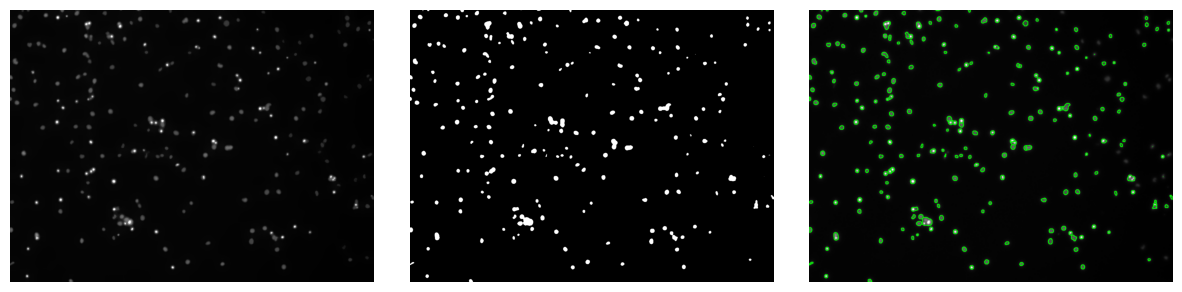

[INFO] 142 unique segments found


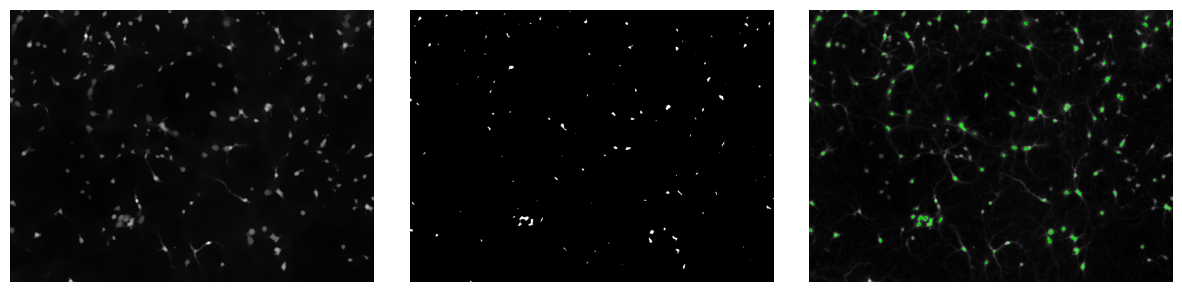

[INFO] 197 unique segments found


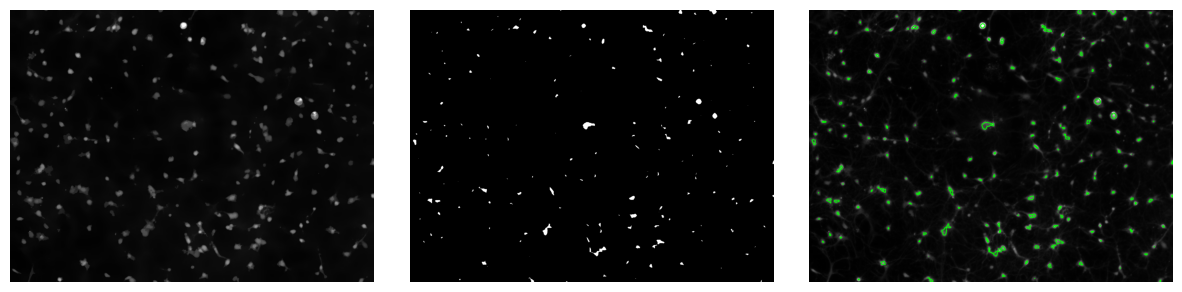

[INFO] 498 unique segments found


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_10303/185479405.py:92: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  contour_table = contour_table.append({'Image Name': image_name, column_names[cntid]: num_contours}, ignore_index=True)


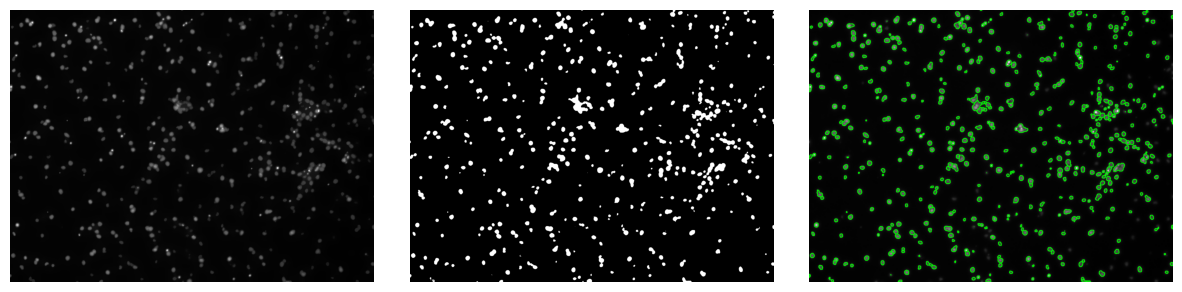

[INFO] 426 unique segments found


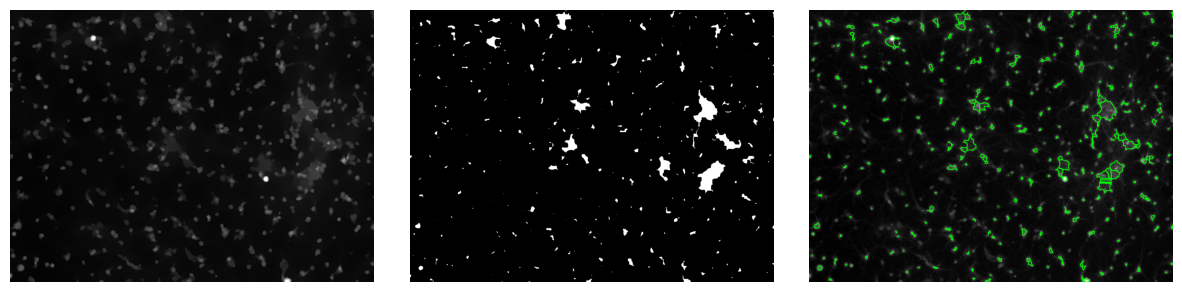

In [23]:
folder_path = "/Users/allisonpickle/Desktop/IL_10_Test"
SR = 20
CR = 20
Erosion_Size = 10
Minimum_Distance = 5
Calculate_Live_Dead(folder_path, SR, CR, Erosion_Size, Minimum_Distance)